# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [2]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [3]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [3]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [4]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C liveness: `gate-current-sanity-check` (B = 0, V_si = 0, T = 1.17 K)

**Read:** device alive on the provided contacts — drain current 9.86–9.94 nA (full 10 nA bias, R_2T ≪ 100 MΩ), Rxx(B_1−B_2) 60–330 Ω. No leakage: both gate currents stay at their pA offsets (BG +25 pA flat; TG −100 pA, drifting to 0 pA over V_tg = 0.4→1.0 V — a ~100 pA/0.6 V change, within the 2400's 1 µA-range offset behaviour and far below the 1 nA trip; watch it on the map, don't alarm). **Gate C: pass.** Two resistance maxima on each gate — TG: −0.21 V (322 Ω) and +0.11 V (244 Ω); BG: −0.26 V (302 Ω) and +0.14 V (273 Ω) — the same pair seen through both gates (position ratios 0.81 / 0.79 ≈ c_bg/c_tg; geometry prior 0.86). Two CNPs in series between B_1 and B_2 → two regions of different intrinsic doping (Δn ≈ 0.6×10¹² from the geometry prior), weak contrast (~3× over the metallic floor). Whether they are two flake domains or a contact-adjacent region is a gatemap question (parallel ridges vs not); series-mosaic is a stacking-read confound to carry forward.


run 0 k_2400_tg +0.00->+1.00 V: R 87-244 Ohm (max at +0.110 V), I_drain 9.86-9.94 nA, I_tg -106..+14 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 1 k_2400_tg +0.00->-0.30 V: R 201-322 Ohm (max at -0.210 V), I_drain 9.86-9.93 nA, I_tg -112..-92 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 2 k_2400_bg +0.00->+2.00 V: R 63-273 Ohm (max at +0.140 V), I_drain 9.86-9.93 nA, I_tg -109..-91 pA, I_bg +16..+38 pA, T 1.166 K, interrupted=False
run 3 k_2400_bg +0.00->-1.30 V: R 86-302 Ohm (max at -0.260 V), I_drain 9.85-9.93 nA, I_tg -109..-89 pA, I_bg +13..+33 pA, T 1.166 K, interrupted=False


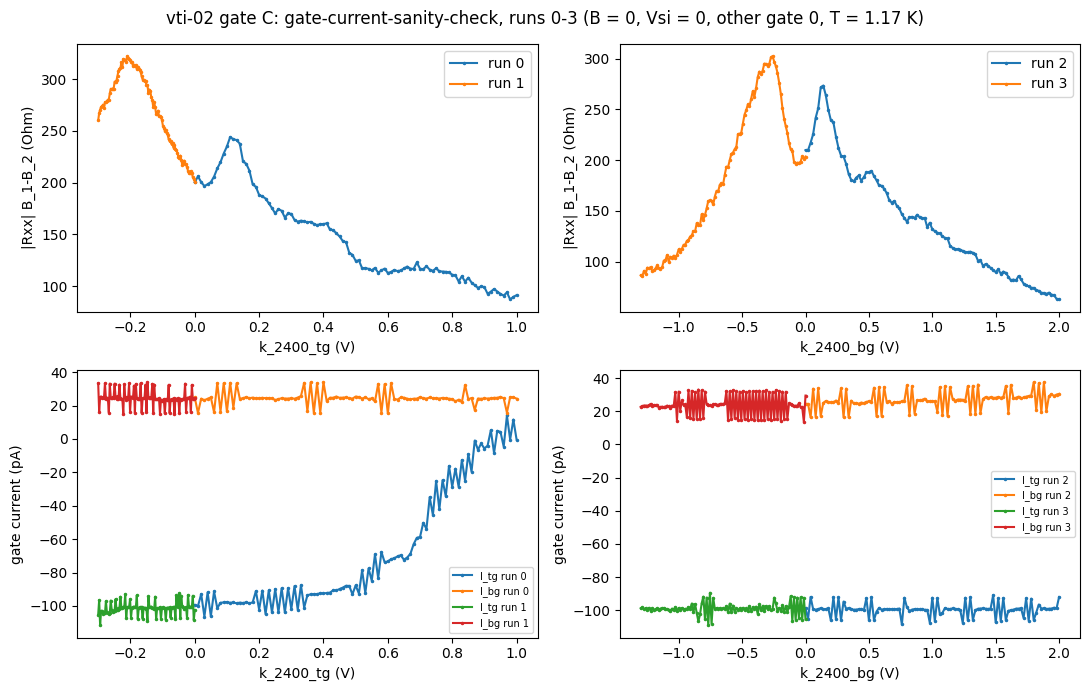

In [6]:
# Gate C — runs 0-3 (gate-current-sanity-check). Raw first: R = (sr1_X/gain)/I_drain per point, gate currents.
from hera.analysis import resolve_channels
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
peaks = {}
for i in range(4):
    r = run(i)
    ch = {c.cid: c for c in resolve_channels(r.meta)}
    V = r.col(r.swept_axis)
    I = r.col("sr0_X") / ch["sr0"].gain
    R = np.abs((r.col("sr1_X") / ch["sr1"].gain) / I)
    i_tg, i_bg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    gate = r.swept_axis.replace("_volt", "")
    k = np.argmax(R); peaks[i] = (gate, V[k], R[k])
    print(f"run {i} {gate} {V[0]:+.2f}->{V[-1]:+.2f} V: R {R.min():.0f}-{R.max():.0f} Ohm (max at {V[k]:+.3f} V), "
          f"I_drain {I.min()*1e9:.2f}-{I.max()*1e9:.2f} nA, I_tg {i_tg.min()*1e12:+.0f}..{i_tg.max()*1e12:+.0f} pA, "
          f"I_bg {i_bg.min()*1e12:+.0f}..{i_bg.max()*1e12:+.0f} pA, T {r.col('T_sample').mean():.3f} K, interrupted={r.interrupted}")
    a = ax[0, 0] if "tg" in gate else ax[0, 1]
    a.plot(V, R, ".-", ms=3, label=f"run {i}"); a.set_xlabel(gate + " (V)"); a.set_ylabel("|Rxx| B_1-B_2 (Ohm)"); a.legend()
    b = ax[1, 0] if "tg" in gate else ax[1, 1]
    b.plot(V, i_tg * 1e12, ".-", ms=3, label=f"I_tg run {i}"); b.plot(V, i_bg * 1e12, ".-", ms=3, label=f"I_bg run {i}")
    b.set_xlabel(gate + " (V)"); b.set_ylabel("gate current (pA)"); b.legend(fontsize=7)
fig.suptitle("vti-02 gate C: gate-current-sanity-check, runs 0-3 (B = 0, Vsi = 0, other gate 0, T = 1.17 K)")
fig.tight_layout(); plt.show()


## Run 5 — 0 T gatemap (`gatemap`) → `cnp-and-dline-calibration`

Raw map (log R, TG fast [−0.3, +1.0] × BG slow [−1.3, +1.2], 20 × 40 mV, sr1 100 µV; run 4 was the same map aborted at 3 min when the ridge railed at 2 kΩ). **Read:** one dominant CNP ridge (A) running from (V_tg, V_bg) ≈ (+1.0, −1.3) to (−0.3, +0.45), plus a fainter **parallel** ridge (B) ≈ 0.19 V lower in V_tg — the second peak of runs 0–3. Ridge A's resistance is 240 Ω near D ≈ 0 and grows to ~2.4 kΩ at raw D ≈ +0.25 V/nm (saturating beyond), i.e. a D-tunable gap; **not a stacking read** (investigation Step 1 addendum: three candidate parents). Fits (ridge position = V_tg vs V_bg rows, so −slope = c_bg/c_tg): ridge A in the operating window |V_bg| < 0.5: slope −0.773 (rms 19 mV); high-D rows: −0.763 (rms 6 mV); ridge B: −0.69 (8 rows, rms 13 mV). **Calibration:** ratio c_bg/c_tg = 0.773 (data-calibrated; prior 0.864, −11 % — plausible hBN-thickness error, not a transposition); c_tg anchored at the 9.5 nm prior (absolute scale = geometry prior, pending a lever-arm check); n_offset = −0.089×10¹²; **D_offset from the R_CNP(D) symmetry** (vertex of the ridge-A resistance minimum, ≈ +0.012 raw) — the one feature that physically locates D = 0. Region B is electron-doped by 0.43×10¹² relative to A: a series-mosaic confound (same template expected, 13 % higher n at the fan density — extra tones at ×1.13). Realized D = 0 window inside the validators: **n = −1.27 … +3.27×10¹²** (TG-limited on both ends). Channel arithmetic: R = (sr1_X/1)/(sr0_X/−1e6).


run 5: 63 rows x 66; R 50-3068 Ohm; prior c_bg/c_tg = 0.864
--- ridge A (main) ---
A all rows: 29/30 rows, Vbg [-2.00,+2.00]: Vtg = -0.7308 Vbg +0.0474; c_bg/c_tg = 0.731; rms 15.5 mV
A high-D rows: 16/16 rows, Vbg [-2.00,-0.60]: Vtg = -0.7630 Vbg +0.0129; c_bg/c_tg = 0.763; rms 5.6 mV
A operating window |Vbg|<0.5: 12/12 rows, Vbg [-0.50,+0.50]: Vtg = -0.7728 Vbg +0.0512; c_bg/c_tg = 0.773; rms 19.2 mV
--- ridge B (parallel, lower Vtg) ---
B all rows: 8/8 rows, Vbg [-2.00,+2.00]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV
B operating window: 8/8 rows, Vbg [-0.50,+0.50]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV

CALIBRATION (ridge A, operating window): ratio 0.773 (prior 0.864, -11%), c_tg 2.796e-03 F/m2 (prior anchor), c_bg 2.161e-03; n_offset -0.0894e12; closure max|n| on fitted line 0.000e12
ridge B density offset relative to A: n_B = -0.426e12 (std 0.026), i.e. region B is electron-doped vs A by 0.43e12
D = 0 line (region A) realized n-window inside v

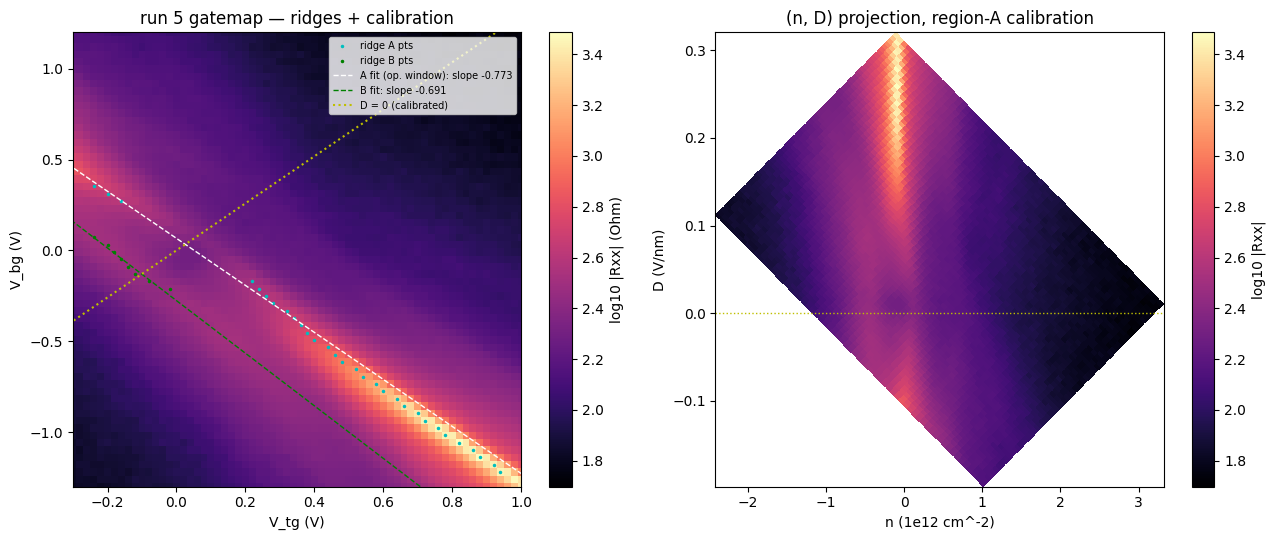

R_CNP(D) minimum: 297 Ohm at raw D = +0.048; parabola vertex raw D = +0.0130 V/nm -> D_offset = -0.0130


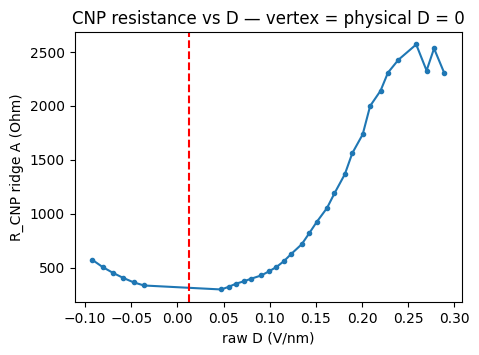

In [7]:
"""cnp-and-dline-calibration on gatemap run 5: per-row ridge extraction (two ridges), ratio fit on the
operating window near D = 0, offsets, closure check, realized D = 0 n-window; writes cal params to JSON."""
import json
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

rid = 5
g = fan_grids(str(Path(file_path) / str(rid))); rg = resistance_grids(g)
R = np.abs(rg.R["sr1"]); Vbg = g.slow
fs = g.meta["fast_setpoints"]; Vtg = np.asarray(fs[0] if isinstance(fs[0], list) else fs)
c_tg0 = stack_capacitance([(9.5, 3)]); c_bg0 = stack_capacitance([(11, 3)])
print(f"run {rid}: {g.nrows} rows x {g.nfast}; R {R.min():.0f}-{R.max():.0f} Ohm; prior c_bg/c_tg = {c_bg0/c_tg0:.3f}")

# ridge extraction: per row, up to two peaks; track continuity from the high-|D| end where ridge A is unambiguous
pts = []   # (Vbg, Vtg, R, ridge)
for i in range(g.nrows):
    r = gaussian_filter1d(R[i], 1.0)
    pk, _ = find_peaks(r, prominence=0.05 * (r.max() - r.min()) + 5)
    pk = [p for p in pk if 1 < p < g.nfast - 2]
    for p in sorted(pk, key=lambda p: -r[p])[:2]:
        pts.append((Vbg[i], Vtg[p], r[p]))
pts = np.array(pts)
# assign to ridges by distance to the high-D fit of ridge A (rows Vbg < -0.6), then refit each
selA = pts[:, 0] < -0.6
cfA0 = np.polyfit(pts[selA, 0], pts[selA, 1], 1)
dist = pts[:, 1] - np.polyval(cfA0, pts[:, 0])
ridgeA = pts[np.abs(dist) < 0.08]; ridgeB = pts[(dist < -0.08) & (dist > -0.45)]

def fit(p, lo, hi, label):
    m = (p[:, 0] >= lo) & (p[:, 0] <= hi)
    x, y = p[m, 0], p[m, 1]
    if len(x) < 4: print(f"{label}: {len(x)} rows, skip"); return None
    keep = np.ones(len(x), bool)
    for _ in range(3):
        cf = np.polyfit(x[keep], y[keep], 1); res = y - np.polyval(cf, x)
        keep = np.abs(res) < 2.5 * max(np.std(res[keep]), 0.01)
    cf = np.polyfit(x[keep], y[keep], 1); res = (y - np.polyval(cf, x))[keep]
    print(f"{label}: {keep.sum()}/{len(x)} rows, Vbg [{lo:+.2f},{hi:+.2f}]: Vtg = {cf[0]:+.4f} Vbg {cf[1]:+.4f}; "
          f"c_bg/c_tg = {-cf[0]:.3f}; rms {np.std(res)*1e3:.1f} mV")
    return cf

print("--- ridge A (main) ---")
cfA_all = fit(ridgeA, -2, 2, "A all rows")
cfA_hiD = fit(ridgeA, -2, -0.6, "A high-D rows")
cfA_op = fit(ridgeA, -0.5, 0.5, "A operating window |Vbg|<0.5")
print("--- ridge B (parallel, lower Vtg) ---")
cfB_all = fit(ridgeB, -2, 2, "B all rows")
cfB_op = fit(ridgeB, -0.5, 0.5, "B operating window")

# calibration: anchor c_tg at the prior (single hBN dielectric, better constrained), set c_bg from the operating-window ratio
cf = cfA_op if cfA_op is not None else cfA_all
ratio = -cf[0]; c_tg = c_tg0; c_bg = ratio * c_tg
n0, _ = calc_nD(cf[1], 0.0, c_tg, c_bg); n_offset = -n0
nA_ridge = calc_nD(np.polyval(cf, ridgeA[:, 0]), ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[0]
print(f"\nCALIBRATION (ridge A, operating window): ratio {ratio:.3f} (prior {c_bg0/c_tg0:.3f}, {100*(ratio/(c_bg0/c_tg0)-1):+.0f}%), "
      f"c_tg {c_tg:.3e} F/m2 (prior anchor), c_bg {c_bg:.3e}; n_offset {n_offset:+.4f}e12; closure max|n| on fitted line {np.abs(nA_ridge).max():.3f}e12")
nB = calc_nD(ridgeB[:, 1], ridgeB[:, 0], c_tg, c_bg, n_offset=n_offset)[0] if len(ridgeB) else np.array([np.nan])
print(f"ridge B density offset relative to A: n_B = {np.nanmedian(nB):+.3f}e12 (std {np.nanstd(nB):.3f}), i.e. region B is {'hole' if np.nanmedian(nB)>0 else 'electron'}-doped vs A by {abs(np.nanmedian(nB)):.2f}e12")
# D = 0 line of region A: V_tg = (c_bg/c_tg) V_bg + V_tg0 where n=0 at ... use calc_gate_voltages
ns = np.linspace(-1.5, 4.5, 601); Vt, Vb = calc_gate_voltages(ns, np.zeros_like(ns), c_tg, c_bg, n_offset=n_offset)
ok = (Vt >= -0.3) & (Vt <= 1.0) & (Vb >= -1.3) & (Vb <= 2.0)
print(f"D = 0 line (region A) realized n-window inside validators: {ns[ok].min():+.2f} .. {ns[ok].max():+.2f} e12; "
      f"CNP at (Vtg, Vbg) = ({calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[0]:+.3f}, {calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[1]:+.3f})")
# D range along ridge A
DA = calc_nD(ridgeA[:, 1], ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[1]
print(f"ridge A spans D = {DA.min():+.3f} .. {DA.max():+.3f} V/nm; peak R vs D: " +
      ", ".join(f"{d:+.2f}:{r:.0f}" for d, r in sorted(zip(np.round(DA, 2), ridgeA[:, 2]))[::6]))
json.dump({"run": rid, "ratio": ratio, "c_tg": c_tg, "c_bg": c_bg, "n_offset": n_offset, "D_offset": float(-D0_raw) if "D0_raw" in globals() else 0.0,
           "slope": cf[0], "intercept": cf[1], "window": "A |Vbg|<0.5", "nB_offset": float(np.nanmedian(nB))},
          open(Path(file_path).parent / "hera_scratch" / "cal_run5.json", "w"), indent=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
m = ax[0].pcolormesh(Vtg, Vbg, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m, ax=ax[0], label="log10 |Rxx| (Ohm)")
ax[0].plot(ridgeA[:, 1], ridgeA[:, 0], "c.", ms=3, label="ridge A pts"); ax[0].plot(ridgeB[:, 1], ridgeB[:, 0], "g.", ms=3, label="ridge B pts")
xx = np.array([Vbg.min(), Vbg.max()])
ax[0].plot(np.polyval(cf, xx), xx, "w--", lw=1, label=f"A fit (op. window): slope {cf[0]:+.3f}")
if cfB_all is not None: ax[0].plot(np.polyval(cfB_all, xx), xx, "g--", lw=1, label=f"B fit: slope {cfB_all[0]:+.3f}")
ax[0].plot(Vt[ok], Vb[ok], "y:", lw=1.5, label="D = 0 (calibrated)")
ax[0].set_xlim(Vtg.min(), Vtg.max()); ax[0].set_ylim(Vbg.min(), Vbg.max()); ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"run {rid} gatemap — ridges + calibration")
# (n, D) projection
N, D = calc_nD(Vtg[None, :], Vbg[:, None], c_tg, c_bg, n_offset=n_offset)
m2 = ax[1].pcolormesh(N, D, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m2, ax=ax[1], label="log10 |Rxx|")
ax[1].axhline(0, color="y", ls=":", lw=1); ax[1].set_xlabel("n (1e12 cm^-2)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("(n, D) projection, region-A calibration")
fig.tight_layout(); plt.show()

# D_offset from the CNP-resistance symmetry in ±D (ridge A only, n within 0.1e12 of the fit line)
rows = []
for i in range(g.nrows):
    vc = cf[0] * Vbg[i] + cf[1]
    if vc < Vtg.min() + 0.03 or vc > Vtg.max() - 0.03: continue
    msk = np.abs(Vtg - vc) < 0.12
    r = gaussian_filter1d(R[i], 1.0); j = np.argmax(np.where(msk, r, -1))
    n_j, D_j = calc_nD(Vtg[j], Vbg[i], c_tg, c_bg, n_offset=n_offset)
    if abs(n_j) < 0.1: rows.append((D_j, r[j]))
rows = np.array(sorted(rows)); k = np.argmin(rows[:, 1]); sel = np.abs(rows[:, 0] - rows[k, 0]) < 0.12
cq = np.polyfit(rows[sel, 0], rows[sel, 1], 2); D0_raw = -cq[1] / (2 * cq[0])
print(f"R_CNP(D) minimum: {rows[k,1]:.0f} Ohm at raw D = {rows[k,0]:+.3f}; parabola vertex raw D = {D0_raw:+.4f} V/nm -> D_offset = {-D0_raw:+.4f}")
plt.figure(figsize=(5, 3.5)); plt.plot(rows[:, 0], rows[:, 1], "o-", ms=3); plt.axvline(D0_raw, color="r", ls="--")
plt.xlabel("raw D (V/nm)"); plt.ylabel("R_CNP ridge A (Ohm)"); plt.title("CNP resistance vs D — vertex = physical D = 0"); plt.show()


## Runs 6–7 — SdH spot checks (`sdh-spot-check`) at D = 0, both carrier signs

Investigation Step 3. Two fixed-(n, D = 0) field sweeps at base T, from the run-5
calibration: **run 6** electron, n = +3.20×10¹² (the D = 0 line's electron reach —
V_tg = +0.984 V, 16 mV under the limit), B 0 → 10 T; **run 7** hole,
n = −1.20×10¹² (the line's hole reach), riding the magnet back 10 → 0.3 T.
Both `sr1` (B_1 − B_2), 50 µV, I_bias = 10 nA, dwell = the magnet driver's 3 s
settle = 10 τ at τ = 0.3 s / 24 dB.

**Each record carries a coarse low-B leg that is undersampled for its own tones**
— run 6 steps 50 mT below 1 T (Δ(1/B) = 0.55 1/T at 0.3 T, against a Nyquist need
of 0.015), run 7 steps 20 mT throughout (Δ(1/B) = 0.22 1/T at 0.3 T). FFT'ing
through those legs folds aliases into the low-frequency band, which is what a
first pass did: the peak set wandered with the cutoff (7.8 → 8.6 → 33 T on run 6).
Everything below is read on the **Nyquist-valid window only** — B ≥ 1.0 T (run 6)
and B ≥ 0.70 T (run 7), where the grid resolves F_L. Raw first, then the read.


run 6
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    electron side: n = +3.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (+0.9836, +1.1661); B 0 -> 10 T uniform-B (50 mT to 1 T, 10 mT above); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    921 of 921 (complete)
  swept:   magnet_field 0 → 10 (monotonic)
   R -32.6 .. 522.5 Ohm  (fill 0.104 of 5 kOhm FS) | T_sample 1.165-1.292 K | F_L = 33.09 T

run 7
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    hole side: n = -1.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (-0.2770, -0.4650); B 10 -> 0.3 T uniform-B 20 mT (ride-down); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    486 of 486 (complete)
  swept:   magnet_field 10 → 0.3 (monotonic)
   R -0.4 .. 575.7 Ohm  (fill 0.115 of 5 kOhm FS) | T_sample 1.175-1.291 K | F_L = 12.41 T



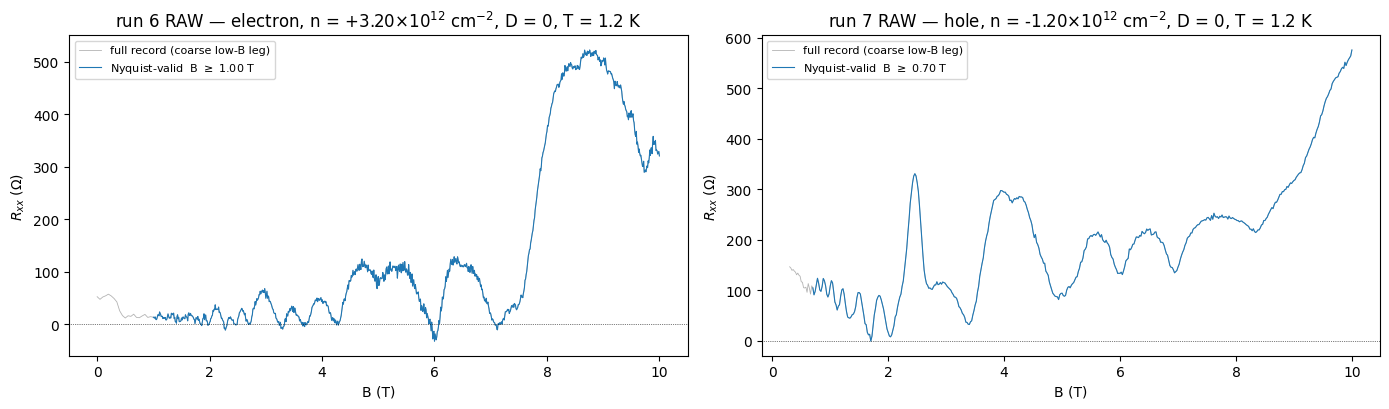

In [4]:
"""Runs 6-7 raw: R_xx(B) from the TSV, gain-divided, full record + Nyquist-valid window."""
from hera.analysis import sdh_onset

I_BIAS = 10.0e-9                  # sr1 drive / 100 MOhm bias resistor
R_FS = 50e-6 / I_BIAS             # 5 kOhm full scale at the 50 uV sensitivity

SPOT = {6: dict(n=+3.20, label="electron", b_valid=1.00, sens=50e-6),
        7: dict(n=-1.20, label="hole",     b_valid=0.70, sens=50e-6)}

spot = {}
for rid, c in SPOT.items():
    r = run(rid)
    B = np.asarray(r.col("magnet_field"), float)
    R = np.asarray(r.col("sr1_X"), float) / I_BIAS            # sr1 gain = 1
    T = np.asarray(r.col("T_sample"), float)
    o = np.argsort(B)
    spot[rid] = dict(B=B[o], R=R[o], T=T[o], F_L=float(luttinger_frequency(abs(c["n"]) * 1e12 * 1e4)), **c)
    print(summarize_run(r))
    print(f"   R {R.min():.1f} .. {R.max():.1f} Ohm  (fill {np.abs(R).max()/R_FS:.3f} of {R_FS/1e3:.0f} kOhm FS)"
          f" | T_sample {T.min():.3f}-{T.max():.3f} K | F_L = {spot[rid]['F_L']:.2f} T\n")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, rid in zip(ax, (6, 7)):
    s = spot[rid]
    m = s["B"] >= s["b_valid"]
    a.plot(s["B"], s["R"], lw=0.6, color="0.7", label="full record (coarse low-B leg)")
    a.plot(s["B"][m], s["R"][m], lw=0.8, color="C0", label=f"Nyquist-valid  B $\\geq$ {s['b_valid']:.2f} T")
    a.axhline(0, color="k", lw=0.5, ls=":")
    a.set_xlabel("B (T)"); a.set_ylabel(r"$R_{xx}$ ($\Omega$)"); a.legend(fontsize=8)
    a.set_title(f"run {rid} RAW — {s['label']}, n = {s['n']:+.2f}$\\times10^{{12}}$ cm$^{{-2}}$, D = 0, T = 1.2 K")
plt.tight_layout(); plt.show()


===== run 6 (electron, n = +3.20e12, F_L = 33.09 T) | window B 1.00-10.0 T, 901 pts, dB 10 mT -> F_nyq 50.0 T
  ⚠ sdh_onset: tone 7.3 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 1.00 T is the record edge, not a measured die-off
sdh_onset: onset_b = 1.00 T (tone 7.3 T) over B [1.00, 10.00] T
  tone    7.3 T: onset  1.00 T  dF  1.11 T  snr_max   95.9  [censored@edge, near-residual, 2x->14.8T, 3x->22.3T, 4x->29.4T, 6x->43.7T, 8x->58.6T, 12x->88.4T, 18x->130.0T]
  tone   22.3 T: onset  1.40 T  dF  1.63 T  snr_max   46.1  [~3x7.3T]
  tone   14.8 T: onset  1.76 T  dF  2.13 T  snr_max   61.5  [~2x7.3T]
  tone   29.4 T: onset  1.76 T  dF  2.14 T  snr_max  115.4  [~4x7.3T]
  tone   88.4 T: onset  5.28 T  dF 11.21 T  snr_max   51.7  [revives-below-gap, ~12x7.3T]
  tone   58.6 T: onset  3.76 T  dF  6.02 T  snr_max   65.5  [~8x7.3T]
  tone  130.0 T: onset  5.58 T  dF 12.64 T  snr_max   21.2  [revives-below-gap, ~18x7.3T]
  tone   43.7 T

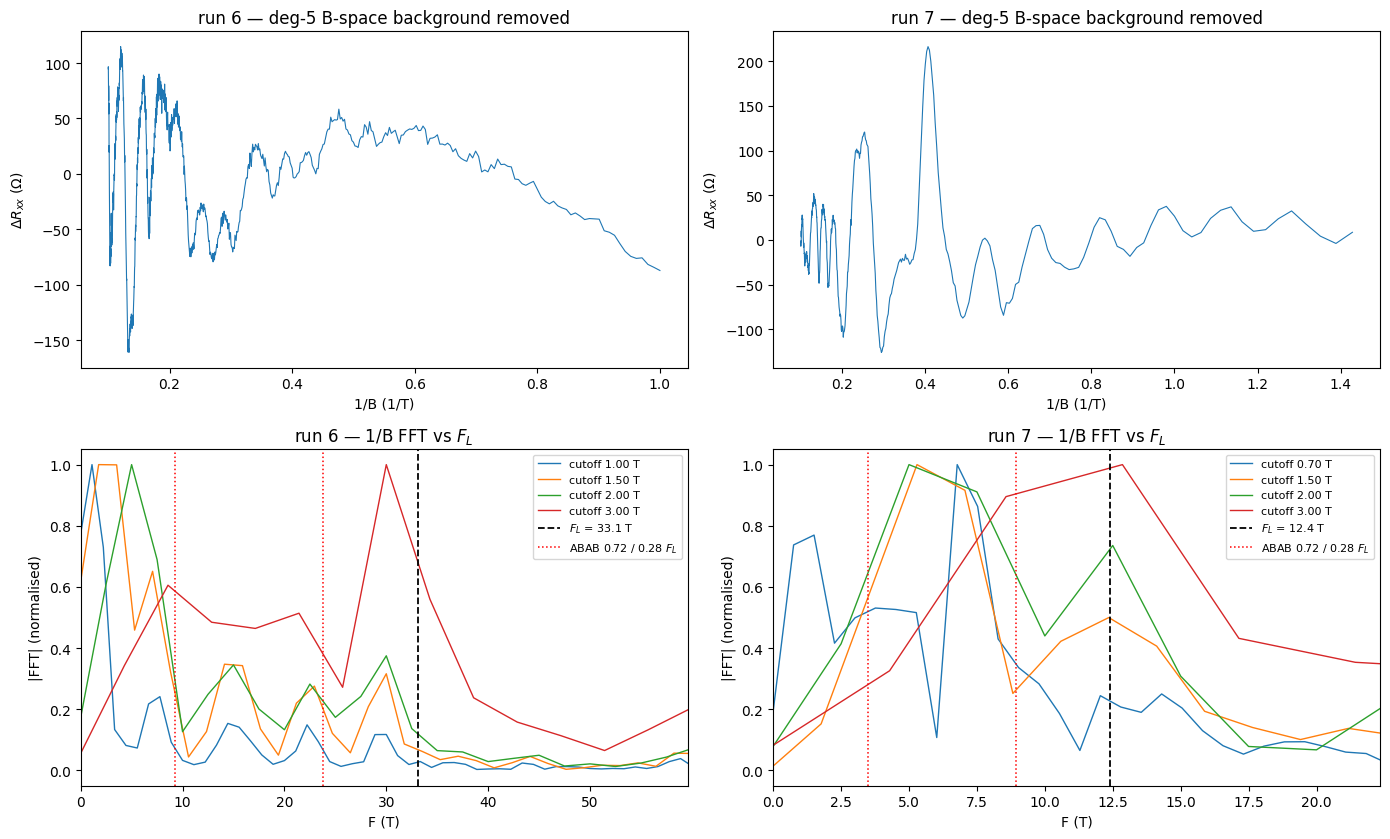

model (hera/models/tetralayer_fs_count README key table, interpolated to n = +3.2e12):
   ABAB  F = 7.2 / 25.9 T  (fractions 0.217 / 0.783; m* 0.027 / 0.060 m_e)
   ABCA  F = 33.1 T = F_L  (singleton; m* 0.076 m_e)
   record resolution dF = 1/(1/1.0 - 1/10.0) = 1.11 T


In [5]:
"""Runs 6-7 read: per-tone onset, 1/B FFT with a cutoff x bg_degree stability sweep,
peak set against F_L and the ABAB 0.28/0.72 template."""
import warnings

fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
tone_tbl = {}
for col, rid in enumerate((6, 7)):
    s = spot[rid]
    m = s["B"] >= s["b_valid"]
    Bv, Rv, F_L = s["B"][m], s["R"][m], s["F_L"]
    dB = np.median(np.diff(Bv))
    print(f"===== run {rid} ({s['label']}, n = {s['n']:+.2f}e12, F_L = {F_L:.2f} T) "
          f"| window B {Bv[0]:.2f}-{Bv[-1]:.1f} T, {len(Bv)} pts, dB {dB*1e3:.0f} mT "
          f"-> F_nyq {Bv[0]**2/(2*dB):.1f} T")

    # --- onset: per-tone, statistical (5-sigma-style) walk down from high B ---
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter("always")
        on = sdh_onset(Rv, Bv, b_lo=s["b_valid"], r_full_scale=R_FS)
    for w in wl:
        print("  ⚠", w.message)
    print(on.summary())
    tone_tbl[rid] = on

    # --- deg-5 background-subtracted trace in 1/B (raw-adjacent view) ---
    a = ax[0, col]
    a.plot(1 / Bv, Rv - np.polyval(np.polyfit(Bv, Rv, 5), Bv), lw=0.8)
    a.set_xlabel("1/B (1/T)"); a.set_ylabel(r"$\Delta R_{xx}$ ($\Omega$)")
    a.set_title(f"run {rid} — deg-5 B-space background removed")

    # --- FFT stability sweep: low-B cutoff x bg_degree ---
    a = ax[1, col]
    print("  FFT peaks  (F [T] | F/F_L | rel amp):")
    for cut in (s["b_valid"], 1.5, 2.0, 3.0):
        for deg in (3, 5, 7):
            f, spec = sdh_fft(Rv[:, None], Bv, b_range=(cut, Bv[-1]), bg_degree=deg,
                              log=False, nfft=4096)
            sp = spec[0]
            if deg == 5:
                a.plot(f, sp / sp.max(), lw=1.0, label=f"cutoff {cut:.2f} T")
            pk = [(round(float(f[i]), 1), round(float(f[i] / F_L), 3), round(float(sp[i] / sp.max()), 2))
                  for i in range(2, len(f) - 2)
                  if sp[i] > sp[i-1] and sp[i] > sp[i+1] and sp[i] > 0.15 * sp.max() and f[i] > 2]
            print(f"    cutoff {cut:>4.2f} T, bg_degree {deg}: {pk}")
    a.axvline(F_L, color="k", ls="--", lw=1.3, label=f"$F_L$ = {F_L:.1f} T")
    a.axvline(0.72 * F_L, color="r", ls=":", lw=1.1, label="ABAB 0.72 / 0.28 $F_L$")
    a.axvline(0.28 * F_L, color="r", ls=":", lw=1.1)
    a.set_xlim(0, 1.8 * F_L); a.set_xlabel("F (T)"); a.set_ylabel("|FFT| (normalised)")
    a.legend(fontsize=8); a.set_title(f"run {rid} — 1/B FFT vs $F_L$")
    print()
plt.tight_layout(); plt.show()

# --- model expectation at the electron spot, for the read below ---
print("model (hera/models/tetralayer_fs_count README key table, interpolated to n = +3.2e12):")
print("   ABAB  F = 7.2 / 25.9 T  (fractions 0.217 / 0.783; m* 0.027 / 0.060 m_e)")
print("   ABCA  F = 33.1 T = F_L  (singleton; m* 0.076 m_e)")
print(f"   record resolution dF = 1/(1/1.0 - 1/10.0) = {1/(1/1.0-1/10.0):.2f} T")


**Read — runs 6 & 7.**

**Acquisition.** Both sides show strong, *well-developed* SdH at base T: the minima
reach R ≈ 0 (run 6 from ≈ 2 T up, run 7 from ≈ 1.5 T), i.e. the device is in the
quantum-Hall regime over most of the window, not the weak sinusoidal-SdH regime.
That is the single most important fact for the read that follows — **a spiky,
strongly non-sinusoidal waveform generates a rich harmonic comb**, and the comb is
frequency-degenerate with the stacking templates. Channel fill is 0.10–0.12 of the
5 kΩ full scale: no clipping, `sdh_onset` flagged no soft-clip truncation.

**Onset is *not* measured on either record.** The carrying tone is `censored@edge`
in both (run 6: 7.3 T, SNR 96, alive at the window's low edge 1.00 T; run 7: 7.0 T,
SNR 56 at 0.70 T). Oscillations persist below where the *grid* can be trusted, so
each `onset_b` is that record's low edge — a **valid lower bound for a fan's
`B_lo`**, not a measured die-off (`landau-fan` step 1, lever 1).

**Run 6 (electron, n = +3.20×10¹², F_L = 33.1 T) — one column cannot decide.**
The peak set is a comb: 7.3, 14.8, 22.3, 29.4, 43.7, 58.6, 88.4 T, and `sdh_onset`
flags every member above the first as k × 7.3 T. Two facts pull against each other:

- 7.3 T is **0.22 F_L**, and the forward model's ABAB *light* tone at n = +3.2×10¹²
  is 7.2 T (fraction 0.217) — a match well inside δF = 1.11 T. So the fundamental
  sits exactly where the ABAB light pocket is predicted.
- But 7.3 T **cannot be the only pocket**: a lone tone carrying all the density
  would need F = F_L = 33.1 T. Reading 7.3 T as the whole Fermi surface implies a
  global density rescale of 4.5×, far outside the 0.8–1.2 lever-arm band — a red
  flag, not a fit (`Verify: Onsager forward-model overlay`). **Something carries
  the other ~78% of the density**, and the ABAB heavy partner is predicted at
  25.9 T — which lands between the comb's 3rd (21.9 T) and 4th (29.2 T) members.
  The observed peaks sit at 22.3 and 29.4 T, i.e. on the comb, not on 25.9 T; but
  a genuine heavy tone within ~1–2 δF of a strong harmonic is not separable here,
  and the recipe forbids screening a tone as a harmonic when doing so breaks the
  partition sum.

So the electron spot check is **uninformative on stacking by itself** — and it is
uninformative for a *nameable* reason: harmonic/template frequency degeneracy on a
single density. The discriminator the investigation prescribes is the one this
record structurally cannot supply — **n-dependence**: a harmonic tracks k·f(n)
exactly, a real pocket follows its own Onsager curve. That is the fan.

**Run 7 (hole, n = −1.20×10¹², F_L = 12.4 T) — suggestive, not decisive.**
Tones at **5.0 and 7.0 T** (both censored at the record edge) plus a strong
**12.3 T** (SNR 112, 0.99 F_L). 5.0 + 7.0 = 12.0 ≈ F_L closes the Luttinger sum,
and the model's ABAB hole pair at n = −1.2×10¹² is ≈ 5.3 / 7.1 T — a close match;
the 12.3 T tone at F_L is then exactly the **symmetry-allowed ABAB inter-block
breakdown / sum tone** the investigation says to *expect* rather than treat as
exotic. Consistent-with ABAB, and nothing more, because: (i) n = −1.2×10¹² is
inside the near-CNP hole exception regime the investigation flags, where the pair
is close and balanced and beat-like; (ii) 7.0 − 5.0 = 2.0 T is only 2.7 δF
(δF = 0.75 T here); (iii) one column, one density — the hole side of the D = 0
line dead-ends at −1.27×10¹² (TG −0.3 V), so it cannot be pushed into the regime
where the templates separate. **No hole-side fan is possible at design density.**

**Decision — the fan runs on the electron side.** It is the only side that reaches
|n| ≳ 2–3×10¹², where the ABAB pair and the ABCA singleton separate (0.22/0.78 F_L
vs 1.00 F_L), and it has the better-resolved record (δF = 1.11 T over B ≥ 1 T vs
0.75 T but capped at F_L = 12.4 T on the hole side). Inherited to the fan:
**B_lo = 1.00 T**, **Δ(1/B) = 0.010 1/T**, **sr1 at 50 µV**, and the 6τ settling
floor on the gate axis. Design arithmetic in the next cell.


In [6]:
"""Fan design (investigation Step 4) — both-axis Nyquist, resolution, dynamic range,
wall-clock. Every lever at its floor; this IS the proposal (landau-fan step 1)."""
import scipy.constants as cst
from hera.analysis import field_invB
from sharpelab_nb.gates import calc_gate_voltages

CAL = dict(c_tg=2.796e-03, c_bg=2.161e-03, n_offset=-0.0894, D_offset=-0.013)  # run 5
TAU = 0.30                                   # sr1 time constant, 24 dB/oct (read at bring-up)
B_LO, B_HI, N_B = 1.00, 10.0, 91             # B_lo = run-6 onset lower bound; B_hi = session cap
n_hi, n_lo, N_n = 3.20, 0.80, 61
FAST_DELAY, SLOW_DELAY = 6 * TAU, 1.0
T_READ = 0.098                               # per-point read overhead, calibrated on run 5

B_vec = field_invB(B_LO, B_HI, N_B)
ns = np.linspace(n_hi, n_lo, N_n)
Vtgs, Vbgs = calc_gate_voltages(ns, np.zeros_like(ns), CAL["c_tg"], CAL["c_bg"],
                                CAL["n_offset"], CAL["D_offset"])
F_L = luttinger_frequency(np.abs(ns) * 1e12 * 1e4)
d_invB = abs(np.median(np.diff(1 / B_vec)))
dn = abs(ns[1] - ns[0])
dn_ray = 4 * cst.e / cst.h / 1e4 / 1e12 * B_LO         # ray spacing at the lowest B read, 1e12 cm^-2
dF = 1 / (1 / B_LO - 1 / B_HI)

print("B AXIS — uniform in 1/B (per-column SdH-FFT fan)")
print(f"  {N_B} rows, {B_vec[0]:.3f} -> {B_vec[-1]:.3f} T ; d(1/B) = {d_invB:.5f} 1/T")
print(f"  samples/period at F_L(n_max) = {F_L[0]:.1f} T : {1/(d_invB*F_L[0]):.2f}   [Nyquist floor 2, target 3]")
print(f"  dB: {B_vec[1]-B_vec[0]*1:.4f} T at the bottom row -> {B_vec[-1]-B_vec[-2]:.3f} T at the top")
print(f"  resolution dF = 1/(1/B_lo - 1/B_hi) = {dF:.2f} T")
print(f"    ABAB heavy (25.9) vs 3rd harmonic of the light tone (21.9): "
      f"{(25.9-21.9)/dF:.1f} x dF  [need > 2]")
print(f"    ABCA singleton (33.1) vs ABAB heavy (25.9):                 {(33.1-25.9)/dF:.1f} x dF")
print(f"  B-window-split halves (F_L-tone origin Verify): dF_half ~ "
      f"{1/(1/B_LO-1/np.sqrt(B_LO*B_HI)):.2f} T — marginal for the 21.9/25.9 pair; the")
print( "    n-dependence screen, not the split, is the primary harmonic discriminator here.")

print("\nn AXIS — ray Nyquist at the lowest B read")
print(f"  {N_n} pts, n {n_hi} -> {n_lo} e12 cm^-2 at D = 0 ; step {dn:.4f}e12")
print(f"  ray spacing g(e/h)B_lo = {dn_ray:.4f}e12 -> {dn_ray/dn:.2f} pts/ray "
      f"[floor 2; still {dn_ray/dn/1.15:.2f} under a 15% lever-arm scale error]")
print(f"  V_tg {Vtgs.min():+.4f} .. {Vtgs.max():+.4f} V  (limit [{-0.3:+.1f}, {1.0:+.1f}], "
      f"{1.0-Vtgs.max():.3f} V margin)")
print(f"  V_bg {Vbgs.min():+.4f} .. {Vbgs.max():+.4f} V  (limit [{-1.3:+.1f}, {2.0:+.1f}])")
print(f"  F_L across the fan: {F_L[-1]:.2f} -> {F_L[0]:.2f} T ; "
      f"periods in the 1/B record at the low-n edge: {F_L[-1]*(1/B_LO-1/B_HI):.1f}")

print("\nDYNAMIC RANGE — worst corner is low n x high B")
print("  anchors: run-5 gatemap R(n=+0.8e12, D=0, B=0) = 145 Ohm ; R(n=+3.2e12) = 56 Ohm")
print("           run 6 (n=+3.2e12) peaked at 523 Ohm at 8.8 T -> MR x9.3")
print("           run 7 (n=-1.2e12, R_B=0 = 144 Ohm - the matched low-|n| anchor) peaked 576 Ohm -> MR x4")
print("  -> worst corner projects to 600-1350 Ohm = 0.12-0.27 of the 5 kOhm FS at 50 uV.")
print("     Keep sr1 at 50 uV (the spot check's validated setting): 3.7x headroom at the")
print("     pessimistic projection, and the high-n/low-B corner still fills ~1% of range,")
print("     which delivered SNR 96 tones on run 6.")

t_pt = FAST_DELAY + T_READ
n_pts = N_B * N_n
retrace = max(np.ptp(Vtgs), np.ptp(Vbgs)) / 0.005 * 0.006
traverse = (B_HI - B_LO) / 0.137 * 60
turn = retrace + SLOW_DELAY + 3.0
tot = n_pts * t_pt + traverse + N_B * turn
print("\nWALL CLOCK  (measurement-dominated regime — landau-fan-vti cost model)")
print(f"  fast_delay {FAST_DELAY:.2f} s (6 tau, n-axis carries the extracted signal) "
      f"+ {T_READ:.3f} s reads (run-5 calibrated) = {t_pt:.3f} s/pt")
print(f"  grid {N_B} x {N_n} = {n_pts} pts          -> {n_pts*t_pt/3600:.2f} h")
print(f"  field traverse {B_HI-B_LO:.0f} T / 0.137 T/min -> {traverse/3600:.2f} h")
print(f"  row turnaround {turn:.1f} s x {N_B}        -> {N_B*turn/3600:.2f} h")
print(f"  TOTAL {tot/3600:.2f} h ; realistic with the session's 10% overrun = {tot*1.1/3600:.2f} h")
print(f"  + positioning 0 -> {B_LO:.1f} T bare ramp = {B_LO/0.137:.0f} min. Ends at 10 T.")


B AXIS — uniform in 1/B (per-column SdH-FFT fan)
  91 rows, 1.000 -> 10.000 T ; d(1/B) = 0.01000 1/T
  samples/period at F_L(n_max) = 33.1 T : 3.02   [Nyquist floor 2, target 3]
  dB: 0.0101 T at the bottom row -> 0.909 T at the top
  resolution dF = 1/(1/B_lo - 1/B_hi) = 1.11 T
    ABAB heavy (25.9) vs 3rd harmonic of the light tone (21.9): 3.6 x dF  [need > 2]
    ABCA singleton (33.1) vs ABAB heavy (25.9):                 6.5 x dF
  B-window-split halves (F_L-tone origin Verify): dF_half ~ 1.46 T — marginal for the 21.9/25.9 pair; the
    n-dependence screen, not the split, is the primary harmonic discriminator here.

n AXIS — ray Nyquist at the lowest B read
  61 pts, n 3.2 -> 0.8 e12 cm^-2 at D = 0 ; step 0.0400e12
  ray spacing g(e/h)B_lo = 0.0967e12 -> 2.42 pts/ray [floor 2; still 2.10 under a 15% lever-arm scale error]
  V_tg +0.2960 .. +0.9836 V  (limit [-0.3, +1.0], 0.016 V margin)
  V_bg +0.2764 .. +1.1661 V  (limit [-1.3, +2.0])
  F_L across the fan: 8.27 -> 33.09 T ; perio